In [1]:
import numpy as np
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

In [91]:
conn = sqlite3.connect('../../../db/object_detection.db')

df = pd.read_sql_query(
    """SELECT seq_name, frame_h, frame_w, altitude, x_left, y_top, width, height, pos_x, pos_y
    FROM boxes
    WHERE altitude != "NODATA" and width > 0 and height > 0
    ORDER BY RANDOM() LIMIT 1000000;""",
    conn
)
print(df.shape)
df.to_csv("box_data.csv", index=False)

(1000000, 10)


In [154]:
# read 1e6 randomly selected bounding boxes + leg positions
df = pd.read_csv("box_data.csv")
df.shape

(1000000, 10)

In [155]:
"unique seq files", df["seq_name"].unique().shape

('unique seq files', (6010,))

In [156]:
df.groupby(by=["frame_h", "frame_w"])["seq_name"].count()

frame_h  frame_w
480      640         21702
720      1280        60434
960      1280       917864
Name: seq_name, dtype: int64

In [157]:
# convert coordinates to relative form
df["pos_x_rel"] = df["pos_x"] / df["frame_w"]
df["pos_y_rel"] = df["pos_y"] / df["frame_h"]

df["x_left_rel"] = df["x_left"] / df["frame_w"]
df["y_top_rel"] = df["y_top"] / df["frame_h"]

df["width_rel"] = df["width"] / df["frame_w"]
df["height_rel"] = df["height"] / df["frame_h"]

df["frame_ratio"] = df["frame_h"] / df["frame_w"]
df["box_ratio"] = df["height"] / df["width"]
df["box_center_x_rel"] = df["x_left_rel"] + df["width_rel"] / 2
df["box_center_y_rel"] = df["y_top_rel"] + df["height_rel"] / 2

df["x_dist"] = df["box_center_x_rel"].apply(lambda x: np.abs(x - 0.5))
df["y_dist"] = df["box_center_y_rel"].apply(lambda x: np.abs(x - 0.5))
df["dist"] = np.linalg.norm(df[["x_dist", "y_dist"]].values, axis=1)

df["pos_x_dist"] = df["pos_x_rel"].apply(lambda x: np.abs(x - 0.5))
df["pos_y_dist"] = df["pos_y_rel"].apply(lambda x: np.abs(x - 0.5))
df["pos_dist"] = np.linalg.norm(df[["pos_x_dist", "pos_y_dist"]].values, axis=1)

df["angle"] = np.arctan2(df["y_dist"].values, df["x_dist"].values)
df["pos_angle"] = np.arctan2(df["pos_y_dist"].values, df["pos_x_dist"].values)

In [158]:
df.head()

,seq_name,frame_h,frame_w,altitude,x_left,y_top,width,height,pos_x,pos_y,...,box_center_x_rel,box_center_y_rel,x_dist,y_dist,dist,pos_x_dist,pos_y_dist,pos_dist,angle,pos_angle
0,record_190507-103206_f_27060_30060.avi.seq,960,1280,290,576,178,100,100,626,228,...,0.489063,0.237500,0.010937,0.262500,0.262728,0.010937,0.262500,0.262728,1.529154,1.529154
1,QA_PG1_H250_office_HD_edg_NV_NoPIR_09_12_56_44...,960,1280,250,470,195,100,100,520,245,...,0.406250,0.255208,0.093750,0.244792,0.262130,0.093750,0.244792,0.262130,1.205049,1.205049
2,PG1_DL_H350_office_Beige_Carpet_30_11_57_23_20...,960,1280,350,110,661,146,108,232,680,...,0.142969,0.744792,0.357031,0.244792,0.432891,0.318750,0.208333,0.380794,0.601017,0.578898
3,PG1_dev_H250_VLC_3mHall_Door2room_1509278087.a...,960,1280,250,0,378,253,117,176,445,...,0.098828,0.454687,0.401172,0.045313,0.403723,0.362500,0.036458,0.364329,0.112474,0.100238
4,PG1_H300_office_HD_stand_NY_NoPIR_22_09_51_33_...,960,1280,300,251,606,100,100,301,656,...,0.235156,0.683333,0.264844,0.183333,0.322108,0.264844,0.183333,0.322108,0.605494,0.605494


In [160]:
l2dist = np.linalg.norm(df[["pos_x_rel", "pos_y_rel"]].values -  df[["box_center_x_rel", "box_center_y_rel"]].values, axis=1)
df = df[(l2dist < 0.1 ) & (df["width_rel"] > 0.05) & (df["height_rel"] > 0.05)]
df.shape

(882105, 28)

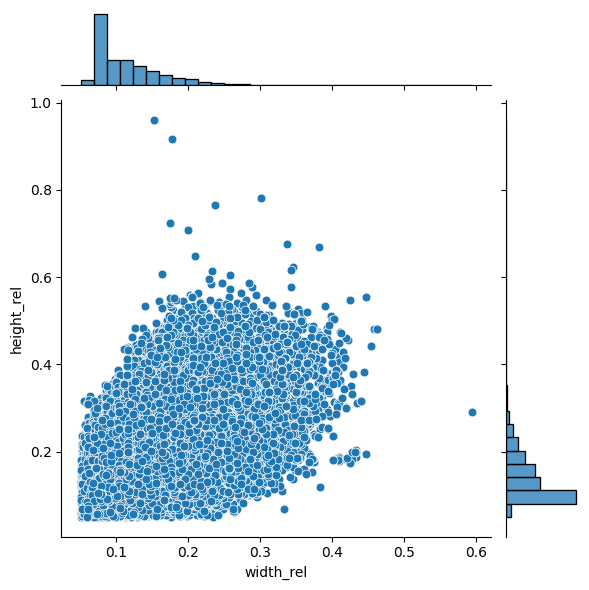

In [161]:
sns.jointplot(data=df, x="width_rel", y="height_rel", marginal_kws=dict(bins=30), s=40)

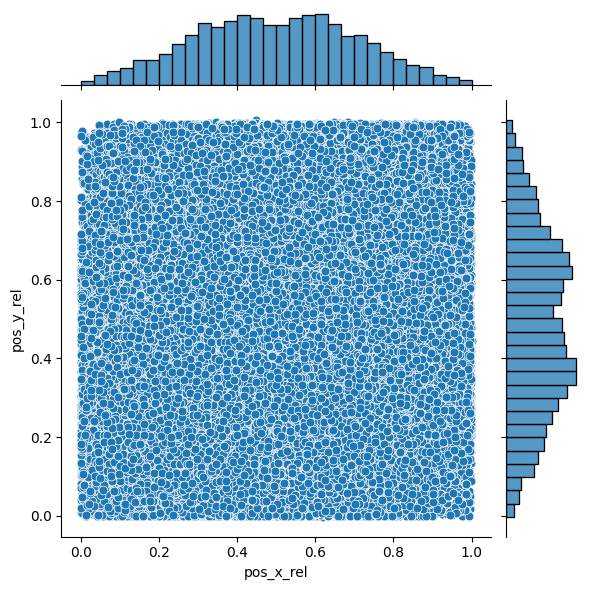

In [162]:
sns.jointplot(data=df, x="pos_x_rel", y="pos_y_rel", marginal_kws=dict(bins=30), s=40)

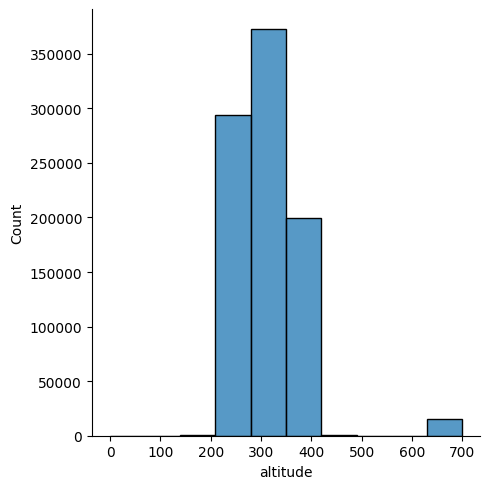

In [163]:
sns.displot(data=df, x="altitude", bins=10)

<Axes: >

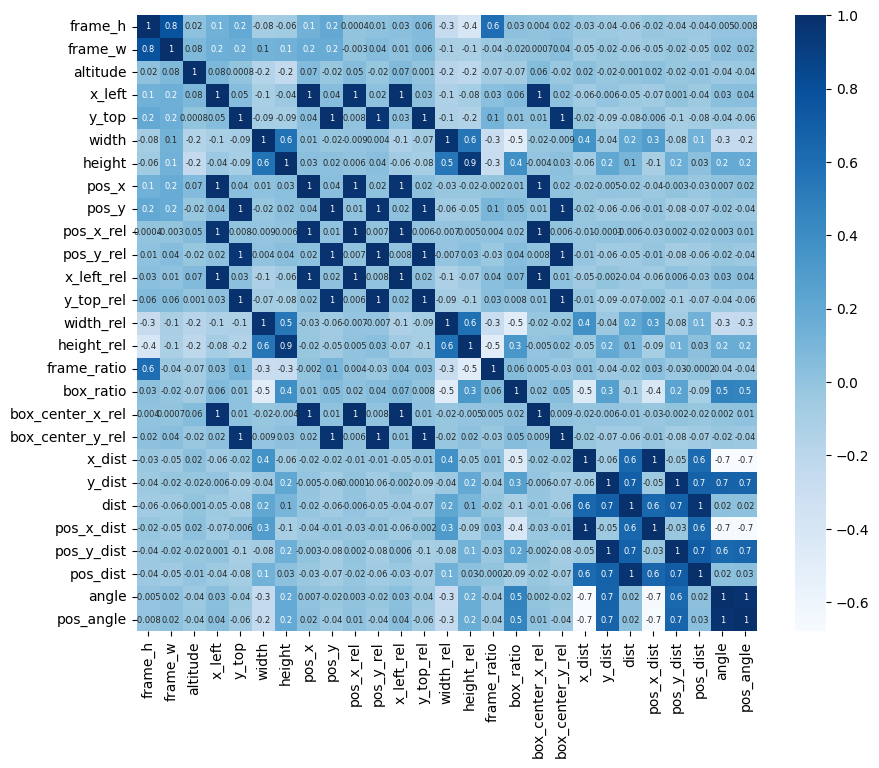

In [164]:
corr = df.drop('seq_name', axis='columns').corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="Blues", annot=True, annot_kws={"size": 6}, fmt='.1g')

In [199]:
def plot_data(df, pred=None):
    df = df.reset_index(drop=True)
    plt.figure(figsize=(6, 6))
    plt.axis("equal")
    for i, row in df.iterrows():
        x, y, w, h, pos_x, pos_y, center_x, center_y = row[[
        "x_left_rel", "y_top_rel", "width_rel", "height_rel", "pos_x_rel", "pos_y_rel", "box_center_x_rel", "box_center_y_rel"]].values

        plt.plot(0.5, 0.5, 'go', markersize=7, label="frame center")
        plt.plot(*np.array([
            [x, y],
            [x, y + h],
            [x + w, y + h],
            [x + w, y],
            [x, y]
        ]).T, c="tab:blue", label='box')
        plt.plot(center_x, center_y, 'bo', markersize=4, label="box center")

        if pred is not None:
            plt.plot(*pred[i], 'c*', markersize=10, label="gt position")
        plt.plot(pos_x, pos_y, 'rx', markersize=7, label="gt position")

    plt.xlim(0, 1)
    plt.ylim(0, 1)

    handles, labels = plt.gca().get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    plt.legend(by_label.values(), by_label.keys(), fontsize=7);

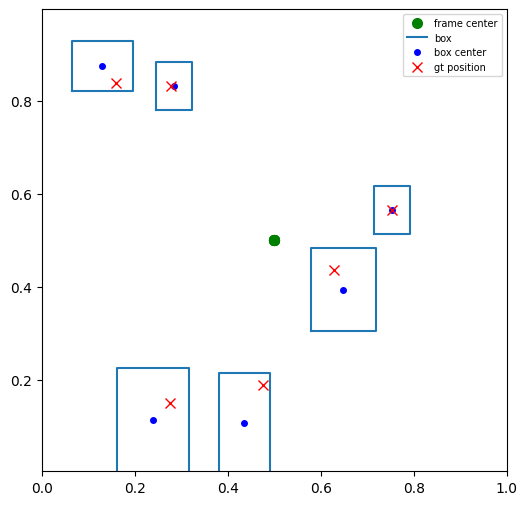

In [195]:
plot_data(df.iloc[5504: 5510])

In [196]:
idxs = np.arange(df.shape[0])
np.random.seed(11)
np.random.shuffle(idxs)

train_idxs = idxs[: int(0.9 * df.shape[0])]
test_idxs = idxs[int(0.9 * df.shape[0]): ]
train_idxs.shape, test_idxs.shape

((793894,), (88211,))

## baseline model

In [174]:
l2_dist = np.linalg.norm(df.iloc[test_idxs][["pos_x_rel", "pos_y_rel"]].values -  df.iloc[test_idxs][["box_center_x_rel", "box_center_y_rel"]].values, axis=1)
l2_dist.mean(), l2_dist.std()

(0.030305047904371805, 0.025722320598623522)

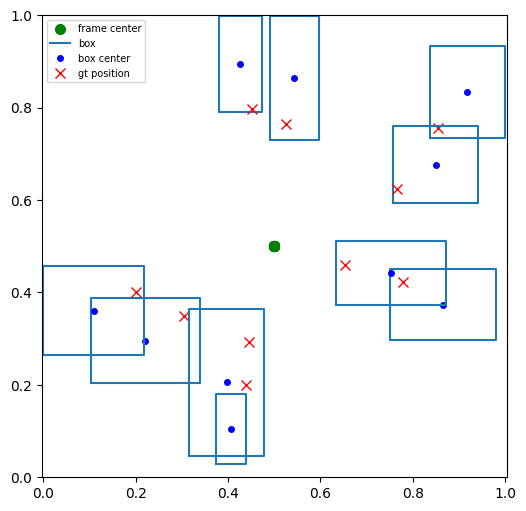

In [175]:
plot_data(df.iloc[test_idxs].iloc[np.argsort(l2_dist)[-10:]])

### base linear regression

In [216]:
train_df = df.iloc[train_idxs]
test_df = df.iloc[test_idxs]

In [217]:
tmp_X_train = train_df[["box_center_x_rel", "box_center_y_rel", "box_ratio", "frame_ratio"]].values
tmp_y_train = train_df[["pos_x_rel", "pos_y_rel"]].values

tmp_X_test = test_df[["box_center_x_rel", "box_center_y_rel", "box_ratio", "frame_ratio"]].values
tmp_y_test = test_df[["pos_x_rel", "pos_y_rel"]].values

In [218]:
pipe = Pipeline([
    ("preprocess", StandardScaler()),
    ("model", Ridge())
])

params = {
    "model__alpha": [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1, 1.5, 2, 5, 10, 20, 50],
}

model_x = GridSearchCV(pipe, params)
model_x.fit(tmp_X_train, tmp_y_train[:, 0])

model_y = GridSearchCV(pipe, params)
model_y.fit(tmp_X_train, tmp_y_train[:, 1])

pred_x = model_x.predict(tmp_X_test)
pred_y = model_y.predict(tmp_X_test)

In [219]:
l2_dist = np.linalg.norm(np.stack([pred_x, pred_y], axis=1) -  tmp_y_test, axis=1)
l2_dist.mean(), l2_dist.std()

(0.027385988944434822, 0.0192817064727809)

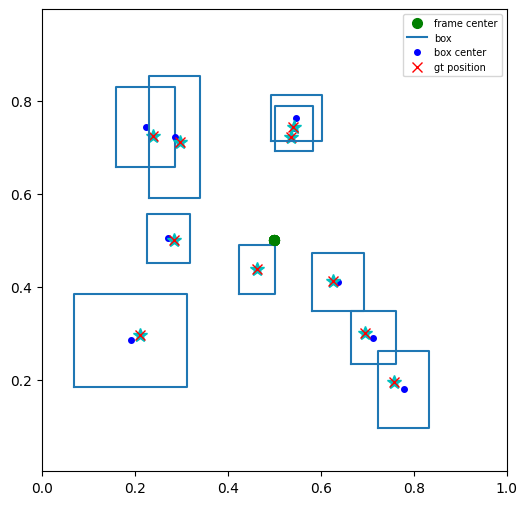

In [220]:
plot_data(test_df.iloc[np.argsort(l2_dist)[:10]], np.stack([pred_x, pred_y], axis=1)[np.argsort(l2_dist)[:10]])

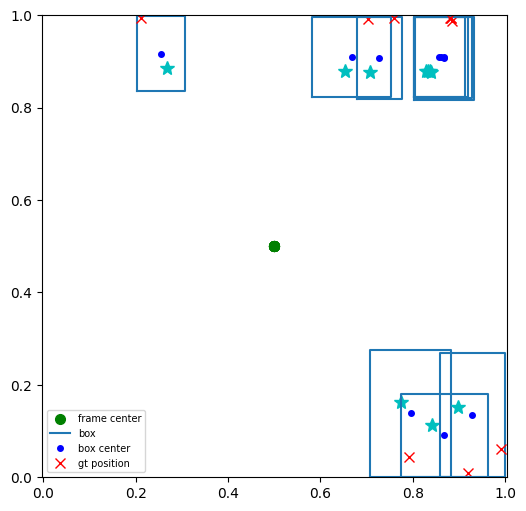

In [221]:
plot_data(test_df.iloc[np.argsort(l2_dist)[-10:]], np.stack([pred_x, pred_y], axis=1)[np.argsort(l2_dist)[-10:]])

In [226]:
model_x.best_params_, model_y.best_params_

({'model__alpha': 0.5}, {'model__alpha': 0.001})

In [239]:
model_x.best_estimator_[-1].intercept_, model_y.best_estimator_[-1].intercept_

(0.49648074573715156, 0.4826170192781125)

In [ ]:
model_x.best_estimator_[-1].coef_, model_y.best_estimator_[-1].coef_

(array([ 0.20497021, -0.000614  , -0.00032278, -0.00022871]),
 array([-0.00031412,  0.2199618 , -0.00037891, -0.00143341]))

In [241]:
alpha = 0.5
model_x = Ridge(alpha)
model_x.fit(tmp_X_train, tmp_y_train[:, 0])
model_y = Ridge(alpha)
model_y.fit(tmp_X_train, tmp_y_train[:, 1])

pred_x = model_x.predict(tmp_X_test)
pred_y = model_y.predict(tmp_X_test)

l2_dist = np.linalg.norm(np.stack([pred_x, pred_y], axis=1) -  tmp_y_test, axis=1)
l2_dist.mean(), l2_dist.std()

(0.027386143451670557, 0.0192814831294723)

In [246]:
alpha = 1
model_x = Ridge(alpha)
model_x.fit(tmp_X_train, tmp_y_train[:, 0])
model_y = Ridge(alpha)
model_y.fit(tmp_X_train, tmp_y_train[:, 1])

pred_x = model_x.predict(tmp_X_test)
pred_y = model_y.predict(tmp_X_test)

l2_dist = np.linalg.norm(np.stack([pred_x, pred_y], axis=1) -  tmp_y_test, axis=1)
l2_dist.mean(), l2_dist.std()

(0.027386302519949383, 0.01928125425730696)